# Challenge 3: Can you change the correlation?

**IBM Quantum | Vishnu Institute of Technology | Qiskit Fall Fest 2026**

For this challenge, students must have a working Python environment with the following packages installed:
- `qiskit` v2.1.0 or newer
- `qiskit-ibm-runtime` v0.40.1 or newer
- `qiskit.visualization`
- `numpy`
- `pylatexenc`

To set up and install the packages above, see the [Install Qiskit](https://quantum.cloud.ibm.com/docs/guides/install-qiskit) guide. In order to run jobs on real quantum computers, you need an IBM Quantum&reg; account (see [Set up your IBM Cloud&reg; account](https://quantum.cloud.ibm.com/docs/guides/cloud-setup)) with an **API key** and an **instance (CRN)**.

In [1]:
# Uncomment and modify this line as needed to install dependencies
#%pip install --upgrade "qiskit[visualization]" qiskit-ibm-runtime numpy pylatexenc

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram

## Introduction

Two qubits can be prepared in a state where their measurement outcomes are strongly correlated. In this challenge we start from the **Bell-state circuit** and add one gate to see whether we can change the relationship between the two measurement outcomes.

### Gates used

**Hadamard ($H$):** puts a qubit in superposition.

**CNOT:** flips the target qubit if the control qubit is $\vert 1\rangle$.

**$X$ gate:** flips a qubit, $\vert 0\rangle \leftrightarrow \vert 1\rangle$.

### Bell state

Applying $H$ on qubit 0 and then $CNOT(q_0, q_1)$ to $\vert 00\rangle$ gives

$$\vert \Phi^+\rangle = \frac{1}{\sqrt{2}}\left(\vert 00\rangle + \vert 11\rangle\right)$$

The qubits are **entangled**: each one alone is random, but together they always agree.

## Qiskit patterns framework

We follow the Qiskit patterns workflow, a general procedure for solving problems with a quantum computer:

1. **Mapping** the problem to quantum circuits
2. **Optimizing** the circuits for the target hardware
3. **Executing** on the hardware
4. **Post-processing** the results

All circuits below use `measure_all()`, so the results are stored in the classical register called `meas`. Remember that Qiskit uses **little-endian** notation: in a bitstring such as `01`, the rightmost bit is qubit 0.

#### 1. Mapping

**Original circuit:** the Bell circuit ($H$, CNOT).

**Modified circuit:** the same circuit with **one added gate**: an $X$ gate on qubit 1, after the CNOT. This uses 3 gates before measurement and exactly 2 qubits.

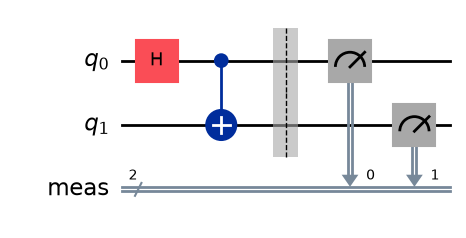

In [3]:
# Original circuit: Bell state
qc_orig = QuantumCircuit(2)
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure_all()
qc_orig.draw("mpl")

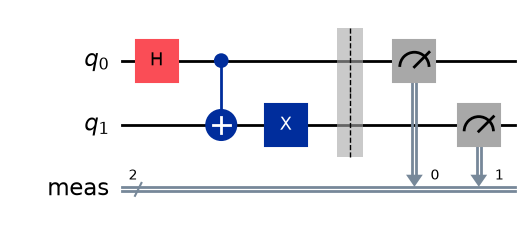

In [4]:
# Modified circuit: Bell circuit + ONE extra X gate on qubit 1
qc_mod = QuantumCircuit(2)
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)          # <-- the one added gate
qc_mod.measure_all()
qc_mod.draw("mpl")

### Think before you run: predictions

- **Original circuit:** the state is $\frac{1}{\sqrt{2}}(\vert 00\rangle + \vert 11\rangle)$, so we expect only `00` and `11`, about 50 shots each.
- **Modified circuit:** $X$ on qubit 1 maps $\vert 00\rangle\rightarrow\vert 01\rangle$ and $\vert 11\rangle\rightarrow\vert 10\rangle$, giving $\frac{1}{\sqrt{2}}(\vert 01\rangle + \vert 10\rangle)$. We expect only `01` and `10`, about 50 shots each.
- **Will the two qubits still produce the same outcomes?** No, in the modified circuit they are always opposite.
- **Will 00 and 11 dominate?** In the original circuit yes; in the modified circuit no.
- **Could 01 and 10 become more frequent?** Yes, they become the dominant outcomes in the modified circuit.

#### 2. Optimizing

Next, we optimize the circuits for the quantum hardware using the transpiler. It assigns the logical qubits to physical qubits on the processor and rewrites the gates in terms of the hardware's native gate set. We choose an optimization level from 0 (none) to 3 (highest); see [Set transpiler optimization level](https://quantum.cloud.ibm.com/docs/guides/set-optimization). The transpiled circuit looks different from the logical one we mapped.

In [5]:
# Load the Qiskit Runtime service
from qiskit_ibm_runtime import QiskitRuntimeService

# Syntax for first saving your credentials. Delete these lines after saving them once,
# and never share a notebook that contains your real API key.
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    instance="<YOUR_INSTANCE_CRN>",
    token="<YOUR_API_KEY>",
    overwrite=True,
    set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_quantum_platform")

# Load saved credentials (use this line on later runs)
# service = QiskitRuntimeService()

# Use the least busy backend, or uncomment the loading of a specific backend.
backend = service.least_busy(operational=True, simulator=False)
# backend = service.backend("ibm_brisbane")
print(backend.name)

ibm_marrakesh


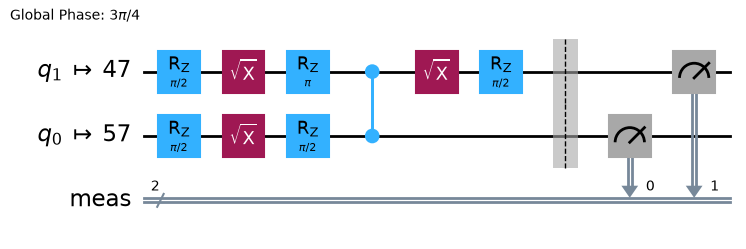

In [6]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

circuits = [qc_orig, qc_mod]
isa_circuits = pm.run(circuits)

isa_circuits[0].draw("mpl", idle_wires=False)

#### 3. Executing

A "Sampler" is a primitive that samples the possible states resulting from a quantum circuit and collects statistics on what is measured and with what probability. We send **all circuits as a single job** with **100 shots** each.

In [7]:
# Load the Runtime primitive
from qiskit_ibm_runtime.executor_sampler import Sampler

sampler = Sampler(mode=backend)

In [8]:
job = sampler.run(isa_circuits, shots=100)
print("Job ID:", job.job_id())

res = job.result()   # waits until the job finishes
all_counts = [r.data.meas.get_counts() for r in res]
counts_orig, counts_mod = all_counts
print("Original:", counts_orig)
print("Modified:", counts_mod)

Job ID: db5qpbklf4us73c4e4qg
Original: {'00': 55, '11': 42, '01': 1, '10': 2}
Modified: {'01': 58, '10': 39, '11': 3}


#### 4. Post-processing

Now we view the results as histograms of the 100 shots of each circuit.

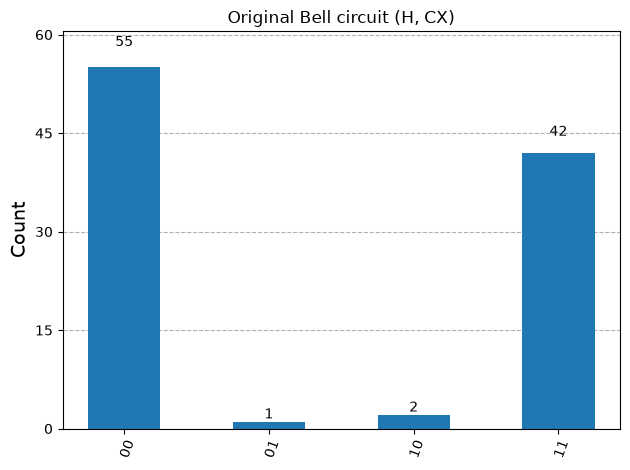

In [9]:
plot_histogram(counts_orig, title="Original Bell circuit (H, CX)")

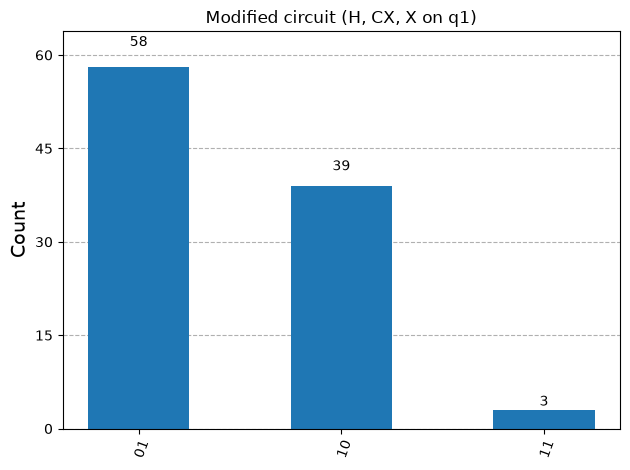

In [10]:
plot_histogram(counts_mod, title="Modified circuit (H, CX, X on q1)")

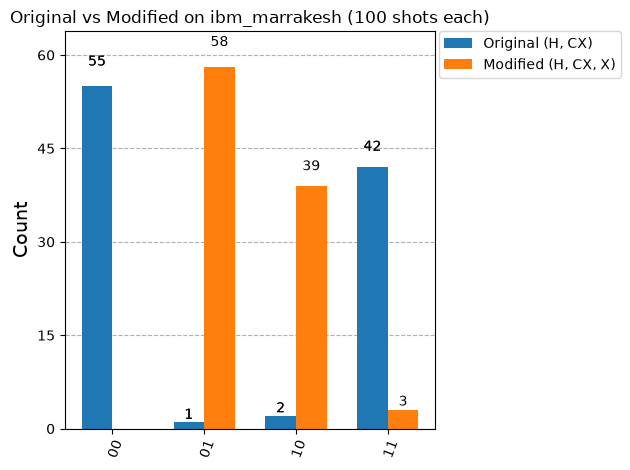

In [11]:
plot_histogram([counts_orig, counts_mod],
               legend=["Original (H, CX)", "Modified (H, CX, X)"],
               title=f"Original vs Modified on {backend.name} (100 shots each)")

### How the modification changed the outcomes

In the original circuit, $H$ puts qubit 0 in superposition and the CNOT copies its value onto qubit 1, so the qubits always agree: `00` or `11`.

The added $X$ gate flips qubit 1 in **both** branches of the superposition, turning `00` into `01` and `11` into `10`. The qubits stay entangled, but the relationship changes from **correlation** (same bits) to **anti-correlation** (opposite bits). The dominant outcomes moved from `00`/`11` to `01`/`10`, as predicted.

An ideal quantum computer would only give the predicted outcomes, but real hardware has noise (gate and readout errors), so a few stray counts are expected.

## Conclusion

### Critical concepts:

- **Entanglement** links qubits so that the measurement result of one is tied to the other.
- The **Bell circuit** ($H$ followed by CNOT) produces perfectly correlated outcomes.
- A single extra **$X$ gate** can switch the correlation to anti-correlation without breaking entanglement.
- Qiskit uses **little-endian** notation, so `01` means qubit 0 is `1` and qubit 1 is `0`.